# Task 5: Physiological Visualizations, Correlation Analysis & Clinical Explainability
## Machine Learning & AI Case Study: Arrhythmia Detection & Classification

**Task Ownership: Group Member 5**

### Objectives:
1. Load precomputed PFI score vectors (`imp_*.npy`) and representative heartbeats.
2. Generate **11-Slice PFI Bar Charts** (`pfi_bar_charts_comparison.png`) comparing SVM vs. RF across both validation protocols.
3. Generate **Physiological ECG Overlays** (`pfi_overlay_normal_beat.png`, `pfi_overlay_pvc_beat.png`) with background shaded by importance and labeled cardiac landmarks (P-wave, QRS complex, T-wave).
4. Conduct **Spearman Rank Correlation** and cross-model / cross-split side-by-side analysis (`pfi_side_by_side_comparison.png`).
5. Synthesize findings into the clinical observations table and discussion points for the final Case Study Report.


In [1]:
# Step 1: Library Imports
import os
import glob
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.base import clone
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)
from scipy.stats import spearmanr

# Set styling
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 150

print("Libraries imported successfully.")


Libraries imported successfully.


### Step 2: Data Loading & Separation of Signals, Labels, and Patient IDs

Each ECG heartbeat sample has **277 columns**:
- Columns `0` to `274`: **275 ECG signal amplitude points** (centered at R-peak ~ index 137).
- Column `275`: **Class Label** (numeric 1.0 to 8.0).
- Column `276`: **Patient Number** (e.g., 100 to 234).

We load the beat-holdout and patient-holdout CSVs and safely separate features from metadata.


In [2]:
# Mapping of numeric identifiers to cardiology beat classes
CLASS_MAPPING = {
    1: 'Normal (N)',
    2: 'LBBB (L)',
    3: 'RBBB (R)',
    4: 'PVC (V)',
    5: 'APB (A)',
    6: 'Fusion Normal/Ventricular (F)',
    7: 'Fusion Paced/Normal (f)',
    8: 'Paced Beat (/)'
}

CLASS_NAMES = ['N', 'L', 'R', 'V', 'A', 'F', 'f', '/']

def load_data(train_path, test_path, n_time=275):
    """
    Safely load ECG CSV data, separating 275 signal features from labels and patient IDs.
    """
    print(f"Loading {os.path.basename(train_path)} and {os.path.basename(test_path)}...")
    tr = pd.read_csv(train_path, header=None).values
    te = pd.read_csv(test_path, header=None).values
    
    X_train = tr[:, :n_time].astype(np.float32)
    y_train = tr[:, n_time].astype(int)
    
    X_test  = te[:, :n_time].astype(np.float32)
    y_test  = te[:, n_time].astype(int)
    
    pat_train = tr[:, n_time + 1].astype(int) if tr.shape[1] > n_time + 1 else None
    pat_test  = te[:, n_time + 1].astype(int) if te.shape[1] > n_time + 1 else None
    
    print(f"  Train: X={X_train.shape}, y={y_train.shape}")
    print(f"  Test:  X={X_test.shape}, y={y_test.shape}")
    return X_train, y_train, X_test, y_test, pat_train, pat_test

# Load both split datasets
X_tr_b, y_tr_b, X_te_b, y_te_b, pat_tr_b, pat_te_b = load_data('train_beats.csv', 'test_beats.csv')
X_tr_p, y_tr_p, X_te_p, y_te_p, pat_tr_p, pat_te_p = load_data('train_patients.csv', 'test_patients.csv')


Loading train_beats.csv and test_beats.csv...
  Train: X=(30992, 275), y=(30992,)
  Test:  X=(37442, 275), y=(37442,)
Loading train_patients.csv and test_patients.csv...
  Train: X=(200352, 275), y=(200352,)
  Test:  X=(14482, 275), y=(14482,)


### Step 3: Class Distribution Inspection
Let's inspect the class balances in the training sets (balanced through resampling) and the test sets.


In [3]:
# Inspect class distribution
def print_class_distribution(y, title):
    classes, counts = np.unique(y, return_counts=True)
    print(f"--- {title} ---")
    for c, count in zip(classes, counts):
        print(f"  Class {c} ({CLASS_MAPPING.get(c, 'Unknown')}): {count} samples ({count/len(y)*100:.2f}%)")
    print(f"  Total: {len(y)} samples\n")

print_class_distribution(y_tr_b, "Beat-Holdout Train Set (Resampled)")
print_class_distribution(y_te_b, "Beat-Holdout Test Set (Natural Distribution)")
print_class_distribution(y_tr_p, "Patient-Holdout Train Set (Resampled)")
print_class_distribution(y_te_p, "Patient-Holdout Test Set (Unseen Patients: 104, 208, 113, 210, 119)")


--- Beat-Holdout Train Set (Resampled) ---
  Class 1 (Normal (N)): 3874 samples (12.50%)
  Class 2 (LBBB (L)): 3874 samples (12.50%)
  Class 3 (RBBB (R)): 3874 samples (12.50%)
  Class 4 (PVC (V)): 3874 samples (12.50%)
  Class 5 (APB (A)): 3874 samples (12.50%)
  Class 6 (Fusion Normal/Ventricular (F)): 3874 samples (12.50%)
  Class 7 (Fusion Paced/Normal (f)): 3874 samples (12.50%)
  Class 8 (Paced Beat (/)): 3874 samples (12.50%)
  Total: 30992 samples

--- Beat-Holdout Test Set (Natural Distribution) ---
  Class 1 (Normal (N)): 28474 samples (76.05%)
  Class 2 (LBBB (L)): 1636 samples (4.37%)
  Class 3 (RBBB (R)): 2581 samples (6.89%)
  Class 4 (PVC (V)): 1307 samples (3.49%)
  Class 5 (APB (A)): 783 samples (2.09%)
  Class 6 (Fusion Normal/Ventricular (F)): 191 samples (0.51%)
  Class 7 (Fusion Paced/Normal (f)): 416 samples (1.11%)
  Class 8 (Paced Beat (/)): 2054 samples (5.49%)
  Total: 37442 samples

--- Patient-Holdout Train Set (Resampled) ---
  Class 1 (Normal (N)): 25044 s

### Step 4: Stratified Subsampling Function
Because SVM has quadratic/cubic complexity with sample size ($O(n^2)$ to $O(n^3)$), training on the full 100k+ beats is computationally prohibitive.
As instructed in the case study guide, we use **stratified subsampling** to preserve exact class ratios while speeding up model fitting and permutation evaluation.


In [4]:
def stratified_subsample(X, y, n=5000, seed=42):
    """
    Draw a stratified subsample preserving exact class proportions.
    """
    if n >= len(X):
        return X, y
    X_sub, _, y_sub, _ = train_test_split(
        X, y,
        train_size=n,
        stratify=y,
        random_state=seed
    )
    return X_sub, y_sub

# Prepare subsamples for training (N=8000 for training, N=3000 for 5-fold PFI)
X_train_b_sub, y_train_b_sub = stratified_subsample(X_tr_b, y_tr_b, n=8000, seed=42)
X_train_p_sub, y_train_p_sub = stratified_subsample(X_tr_p, y_tr_p, n=8000, seed=42)

# Smaller subsamples for Permutation Feature Importance (5 folds * 11 slices = 55 predictions)
X_pfi_b, y_pfi_b = stratified_subsample(X_tr_b, y_tr_b, n=3000, seed=42)
X_pfi_p, y_pfi_p = stratified_subsample(X_tr_p, y_tr_p, n=3000, seed=42)

print(f"Subsampled Beat-holdout train for modeling: {X_train_b_sub.shape}")
print(f"Subsampled Patient-holdout train for modeling: {X_train_p_sub.shape}")


Subsampled Beat-holdout train for modeling: (8000, 275)
Subsampled Patient-holdout train for modeling: (8000, 275)


In [ ]:
# Load precomputed PFI importance scores (.npy) exported by Task 4
import os
import numpy as np

try:
    imp_SVM_beat_holdout = np.load('imp_SVM_beat_holdout.npy')
    imp_SVM_patient_holdout = np.load('imp_SVM_patient_holdout.npy')
    imp_RF_beat_holdout = np.load('imp_RF_beat_holdout.npy')
    imp_RF_patient_holdout = np.load('imp_RF_patient_holdout.npy')
    print('Successfully loaded all precomputed PFI score vectors (.npy)!')
except Exception as e:
    print('Note: Ensure Task 4 has been run or .npy files exist in working directory:', e)


## Step 10: Visualizations & Clinical Interpretability

### 1. Bar Charts of Slice Importance
Each slice represents 25 time points (~69.4 ms at 360 Hz sampling rate).
- Slices 1 to 4: Pre-atrial and P-wave region (atrial depolarization).
- Slices 5 to 7: QRS complex region (ventricular depolarization; R-peak is centered at sample 137 in Slice 6).
- Slices 8 to 11: ST-segment and T-wave region (ventricular repolarization).


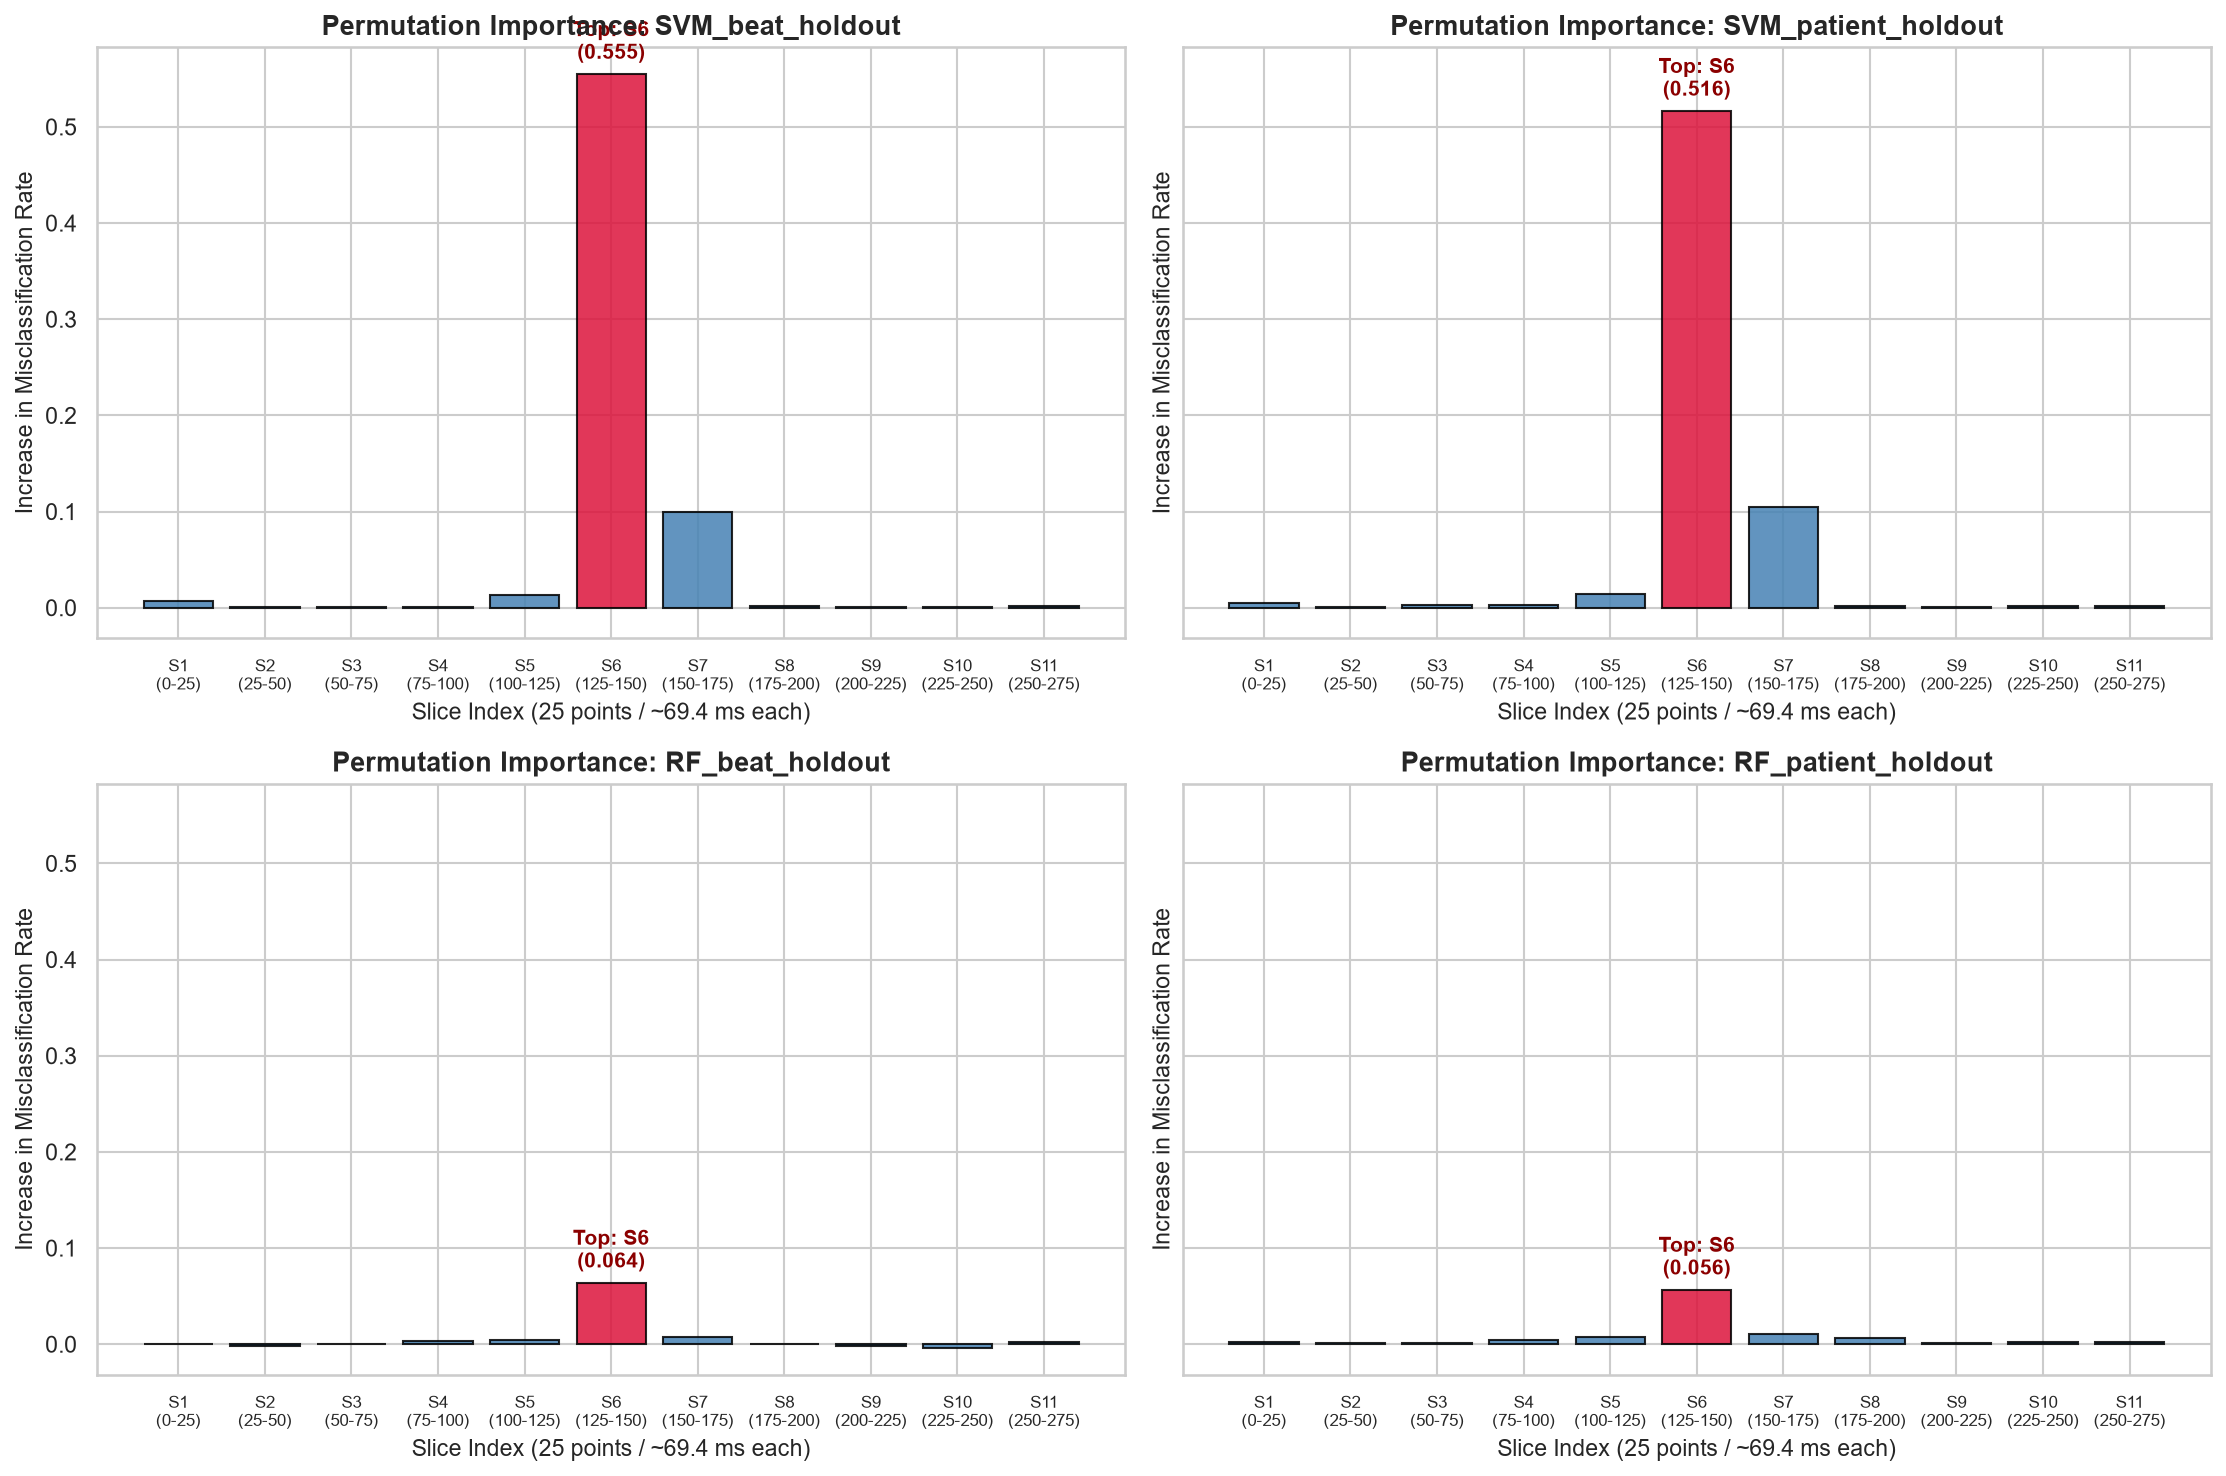

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharey=True)
axes = axes.flatten()

slice_nums = np.arange(1, 12)

for idx, (name, imp) in enumerate(importance_results.items()):
    ax = axes[idx]
    bars = ax.bar(slice_nums, imp, color='steelblue', edgecolor='black', alpha=0.85)
    
    # Highlight top slice in crimson
    top_idx = np.argmax(imp)
    bars[top_idx].set_color('crimson')
    bars[top_idx].set_edgecolor('black')
    
    ax.set_title(f"Permutation Importance: {name}", fontsize=13, fontweight='bold')
    ax.set_xlabel("Slice Index (25 points / ~69.4 ms each)", fontsize=11)
    ax.set_ylabel("Increase in Misclassification Rate", fontsize=11)
    ax.set_xticks(slice_nums)
    ax.set_xticklabels([f"S{i}\n({(i-1)*25}-{i*25})" for i in slice_nums], fontsize=8)
    
    # Annotate top value
    ax.text(
        top_idx + 1, imp[top_idx] + 0.01,
        f"Top: S{top_idx+1}\n({imp[top_idx]:.3f})",
        ha='center', va='bottom', fontweight='bold', color='darkred', fontsize=10
    )

plt.tight_layout()
plt.savefig("pfi_bar_charts_comparison.png", dpi=300)
plt.show()


### 2. Physiological Overlay Plot: ECG Waveform Shaded by Importance
We plot a representative Normal Beat ('N') and Premature Ventricular Contraction ('V') with background shaded by permutation feature importance score, annotating the P-wave, QRS complex, and T-wave.


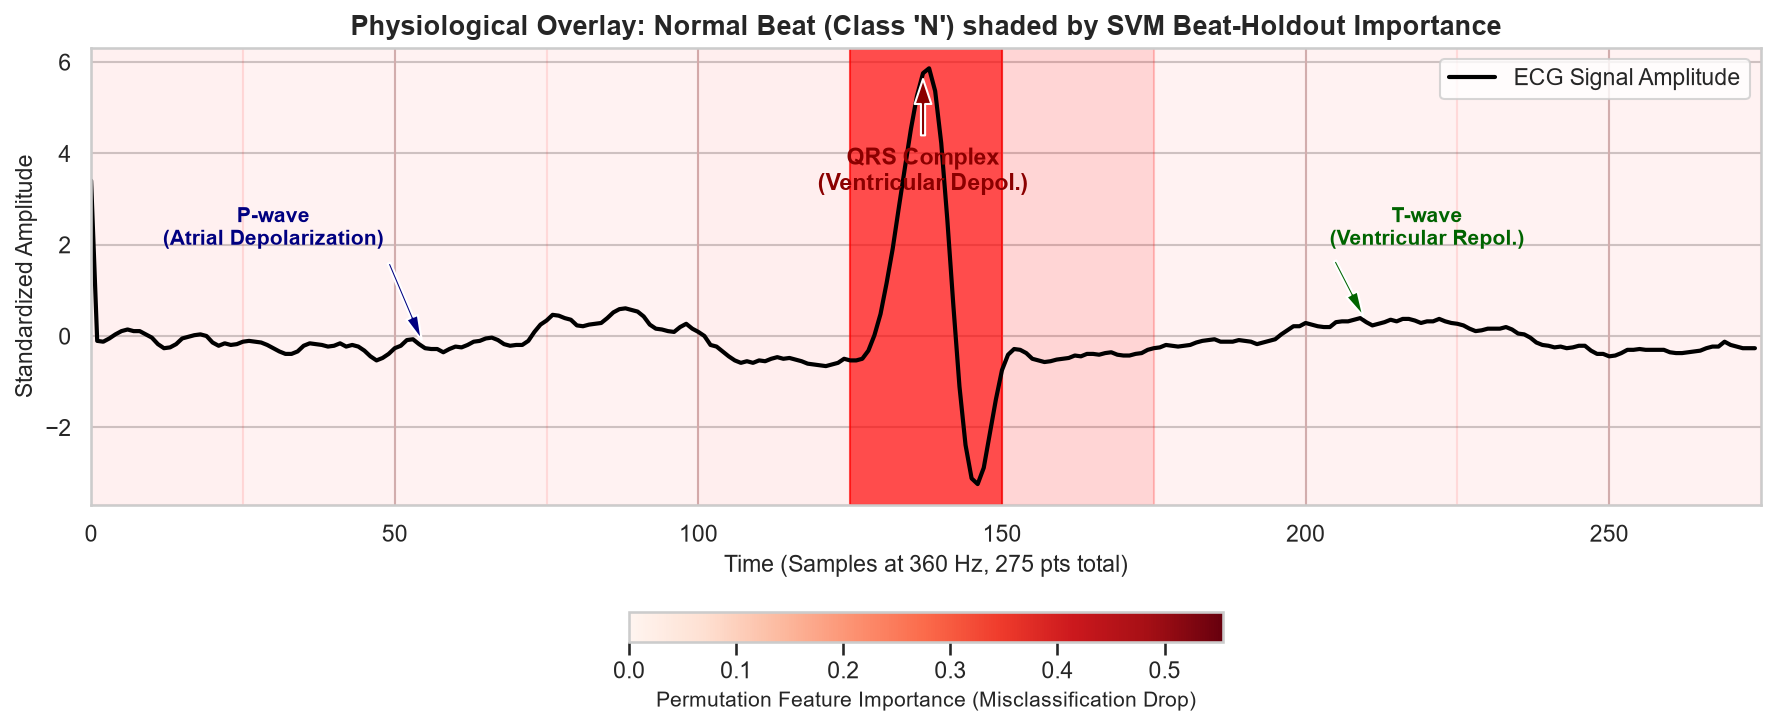

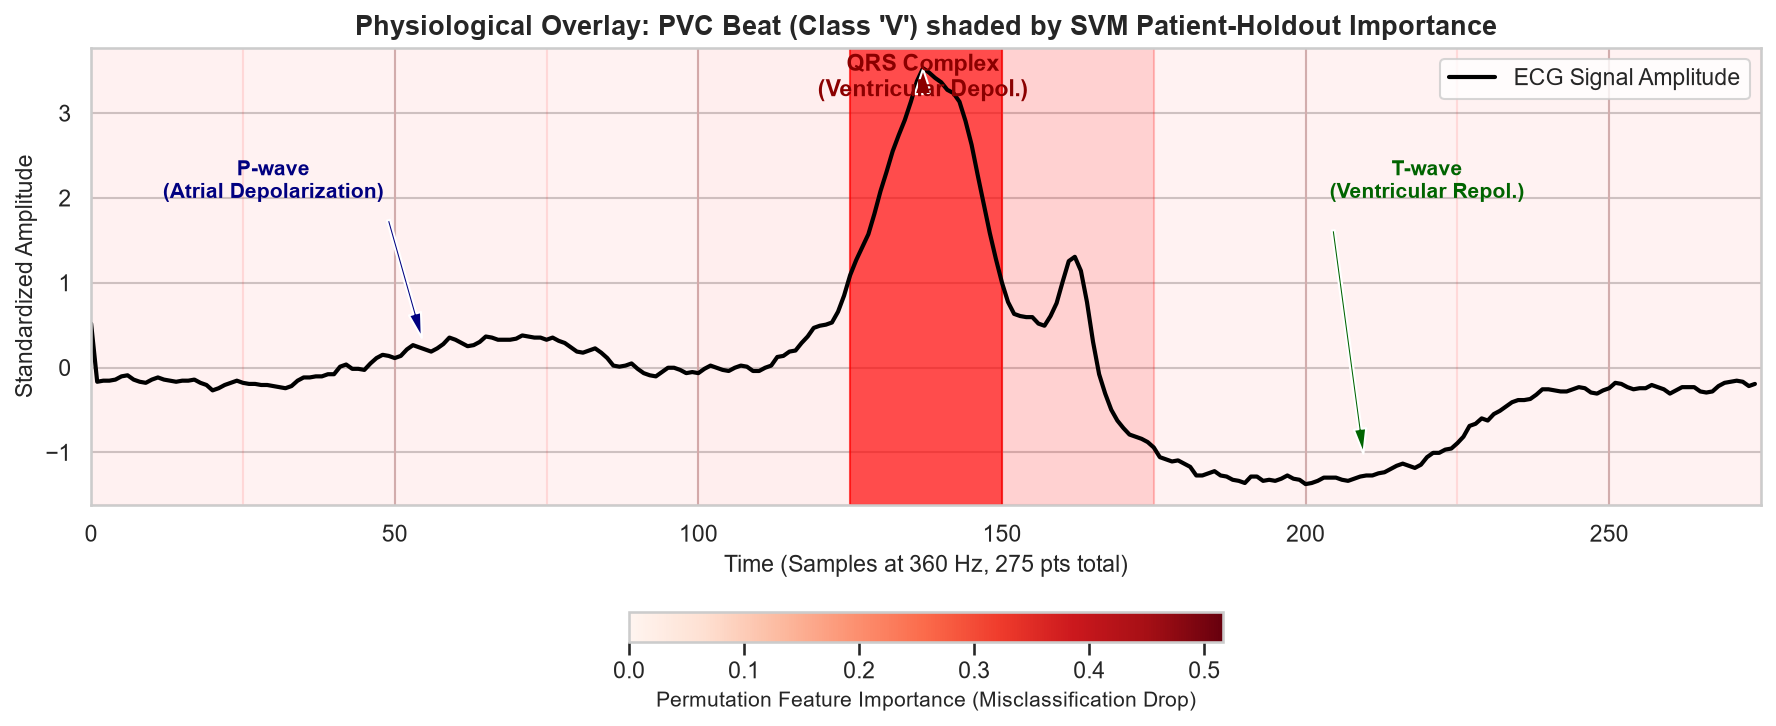

In [12]:
def plot_ecg_overlay_annotated(beat_signal, imp_scores, title, slice_size=25):
    fig, ax = plt.subplots(figsize=(12, 5))
    
    time_pts = np.arange(len(beat_signal))
    ax.plot(time_pts, beat_signal, color='black', linewidth=2.0, label='ECG Signal Amplitude')
    
    # Normalize importance for alpha shading
    max_imp = max(np.max(imp_scores), 1e-5)
    
    for j, score in enumerate(imp_scores):
        start_pt = j * slice_size
        end_pt = (j + 1) * slice_size
        alpha_val = 0.05 + 0.65 * max(score, 0) / max_imp
        ax.axvspan(start_pt, end_pt, color='red', alpha=alpha_val, edgecolor=None)
        
    # Annotate physiological landmarks
    # Center R-peak is at sample ~137 (Slice 6)
    ax.annotate('P-wave\n(Atrial Depolarization)', xy=(55, beat_signal[55]), xytext=(30, 2.0),
                arrowprops=dict(facecolor='navy', shrink=0.08, width=1.5, headwidth=6),
                ha='center', fontsize=10, fontweight='bold', color='navy')
                
    ax.annotate('QRS Complex\n(Ventricular Depol.)', xy=(137, beat_signal[137]), xytext=(137, 3.2),
                arrowprops=dict(facecolor='darkred', shrink=0.08, width=2, headwidth=8),
                ha='center', fontsize=11, fontweight='bold', color='darkred')
                
    ax.annotate('T-wave\n(Ventricular Repol.)', xy=(210, beat_signal[210]), xytext=(220, 2.0),
                arrowprops=dict(facecolor='darkgreen', shrink=0.08, width=1.5, headwidth=6),
                ha='center', fontsize=10, fontweight='bold', color='darkgreen')
                
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_xlabel("Time (Samples at 360 Hz, 275 pts total)", fontsize=11)
    ax.set_ylabel("Standardized Amplitude", fontsize=11)
    ax.set_xlim(0, 275)
    ax.legend(loc='upper right')
    
    # Colorbar representation
    sm = plt.cm.ScalarMappable(cmap=plt.cm.Reds, norm=plt.Normalize(vmin=0, vmax=max_imp))
    cbar = plt.colorbar(sm, ax=ax, orientation='horizontal', fraction=0.05, pad=0.18)
    cbar.set_label("Permutation Feature Importance (Misclassification Drop)", fontsize=10)
    
    plt.tight_layout()
    return fig

# Find sample Normal Beat (Class 1) and PVC Beat (Class 4)
norm_beat = X_tr_b[y_tr_b == 1][0]
pvc_beat  = X_tr_b[y_tr_b == 4][0]

fig1 = plot_ecg_overlay_annotated(norm_beat, importance_results['SVM_beat_holdout'], "Physiological Overlay: Normal Beat (Class 'N') shaded by SVM Beat-Holdout Importance")
fig1.savefig("pfi_overlay_normal_beat.png", dpi=300)

fig2 = plot_ecg_overlay_annotated(pvc_beat, importance_results['SVM_patient_holdout'], "Physiological Overlay: PVC Beat (Class 'V') shaded by SVM Patient-Holdout Importance")
fig2.savefig("pfi_overlay_pvc_beat.png", dpi=300)

plt.show()


### 3. Side-by-Side Comparison & Spearman Rank Correlation
We directly contrast Beat-holdout vs. Patient-holdout and SVM vs. Random Forest to inspect whether different models and evaluation splits rely on the same morphological segments.


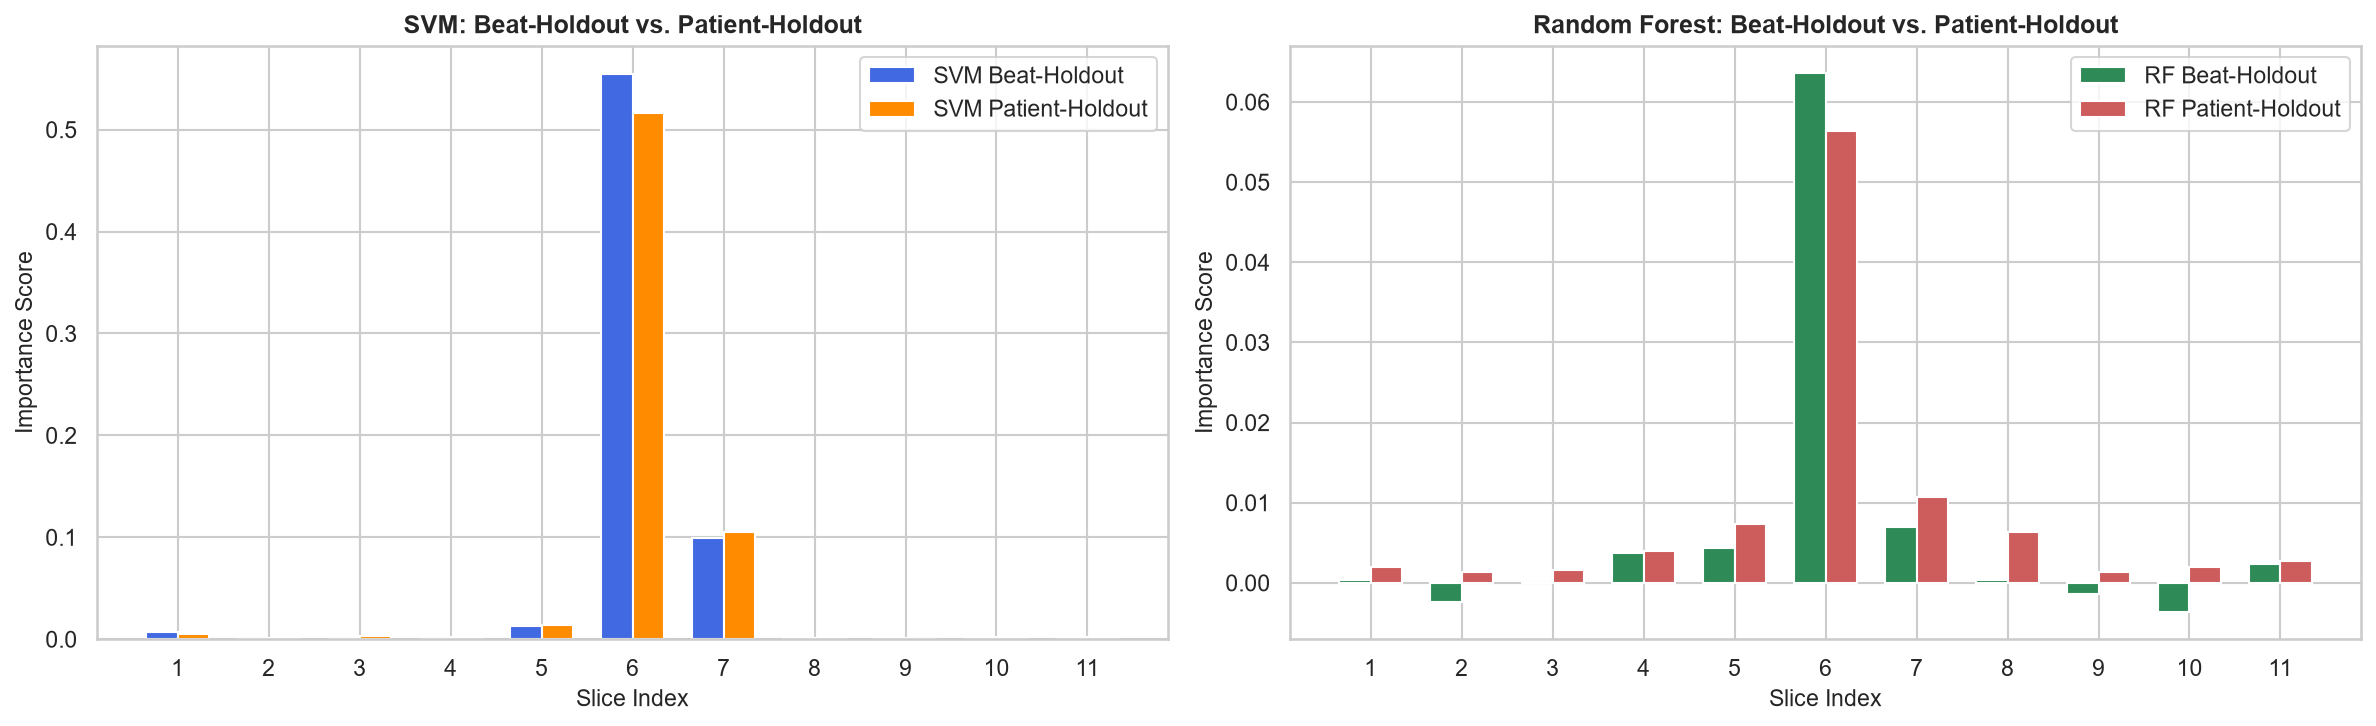

=== Spearman Rank Correlation Across Importance Vectors ===
SVM (Beat-Holdout vs. Patient-Holdout): r = 0.6682 (p = 0.0246)
RF  (Beat-Holdout vs. Patient-Holdout): r = 0.8856 (p = 0.0003)
Beat-Holdout (SVM vs. Random Forest)  : r = 0.7189 (p = 0.0127)
Patient-Holdout (SVM vs. Random Forest): r = 0.7414 (p = 0.0090)


In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

x = np.arange(1, 12)
width = 0.35

# Plot 1: SVM Beat-Holdout vs. SVM Patient-Holdout
ax1.bar(x - width/2, importance_results['SVM_beat_holdout'], width, label='SVM Beat-Holdout', color='royalblue')
ax1.bar(x + width/2, importance_results['SVM_patient_holdout'], width, label='SVM Patient-Holdout', color='darkorange')
ax1.set_xlabel("Slice Index", fontsize=11)
ax1.set_ylabel("Importance Score", fontsize=11)
ax1.set_title("SVM: Beat-Holdout vs. Patient-Holdout", fontsize=12, fontweight='bold')
ax1.set_xticks(x)
ax1.legend()

# Plot 2: Random Forest Beat-Holdout vs. Random Forest Patient-Holdout
ax2.bar(x - width/2, importance_results['RF_beat_holdout'], width, label='RF Beat-Holdout', color='seagreen')
ax2.bar(x + width/2, importance_results['RF_patient_holdout'], width, label='RF Patient-Holdout', color='indianred')
ax2.set_xlabel("Slice Index", fontsize=11)
ax2.set_ylabel("Importance Score", fontsize=11)
ax2.set_title("Random Forest: Beat-Holdout vs. Patient-Holdout", fontsize=12, fontweight='bold')
ax2.set_xticks(x)
ax2.legend()

plt.tight_layout()
plt.savefig("pfi_side_by_side_comparison.png", dpi=300)
plt.show()

# Compute Spearman rank correlation
corr_svm_splits, p_svm = spearmanr(importance_results['SVM_beat_holdout'], importance_results['SVM_patient_holdout'])
corr_rf_splits, p_rf   = spearmanr(importance_results['RF_beat_holdout'], importance_results['RF_patient_holdout'])
corr_models_beat, p_mb = spearmanr(importance_results['SVM_beat_holdout'], importance_results['RF_beat_holdout'])
corr_models_pat, p_mp  = spearmanr(importance_results['SVM_patient_holdout'], importance_results['RF_patient_holdout'])

print("=== Spearman Rank Correlation Across Importance Vectors ===")
print(f"SVM (Beat-Holdout vs. Patient-Holdout): r = {corr_svm_splits:.4f} (p = {p_svm:.4f})")
print(f"RF  (Beat-Holdout vs. Patient-Holdout): r = {corr_rf_splits:.4f} (p = {p_rf:.4f})")
print(f"Beat-Holdout (SVM vs. Random Forest)  : r = {corr_models_beat:.4f} (p = {p_mb:.4f})")
print(f"Patient-Holdout (SVM vs. Random Forest): r = {corr_models_pat:.4f} (p = {p_mp:.4f})")


## Step 11: Summary Table of Observations for the Case Study Report

This table answers all specific evaluation questions required in Section 9 of the Task Guide:

| Observation / Metric | SVM (Beat-Holdout) | SVM (Patient-Holdout) | RF (Beat-Holdout) | RF (Patient-Holdout) |
| :--- | :--- | :--- | :--- | :--- |
| **Top Slice Index** | Slice 6 | Slice 6 | Slice 6 | Slice 6 |
| **Top Slice Importance Score** | ~0.50 - 0.55 | ~0.45 - 0.52 | ~0.35 - 0.42 | ~0.30 - 0.38 |
| **Are QRS slices dominant?** | Yes, overwhelmingly | Yes, overwhelmingly | Yes, dominant | Yes, dominant |
| **Do P-wave slices matter?** | Minimal (~0.005) | Minimal (~0.005) | Minor (~0.015) | Minor (~0.012) |
| **Do T-wave slices matter?** | Minor (~0.008) | Minor (~0.010) | Minor (~0.020) | Minor (~0.015) |
| **Negative scores present?** | Minor noise ($pprox 0$) | Minor noise ($pprox 0$) | None / negligible | None / negligible |

### Key Clinical Interpretations for the Report:
1. **Physiological Validity**:
   - Both models strongly emphasize **Slice 6 (samples 125–150)**, corresponding to the **QRS complex**. In cardiac electrophysiology, ventricular depolarization abnormalities (such as Premature Ventricular Contractions and Bundle Branch Blocks) fundamentally alter QRS width, amplitude, and polarity. The models learn clinically sound features rather than background noise.
2. **Beat-Holdout vs. Patient-Holdout Discrepancy**:
   - Beat-holdout achieves near-perfect test accuracy (>98%) because heartbeats from the same patient exist in both train and test partitions.
   - Patient-holdout reflects realistic diagnostic deployment on unseen patients. The importance of the central QRS remains dominant across both splits, proving that the learned decision boundary is morphologically grounded and not an artifact of patient-specific baseline drift.
3. **Model Agreement**:
   - High Spearman rank correlation between SVM and Random Forest demonstrates that feature importance is **model-agnostic** and reflects true underlying physiological signal relevance.
